<a href="https://colab.research.google.com/github/gguex/ISH_ressources_cours_ML/blob/main/TP06c_corrige.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# TP 6 : Corrigé de l'exercice

Adaptation du code du TP aux données `BreastCancer.csv`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
# Pour standardiser
from sklearn.preprocessing import StandardScaler
# Les méthodes de réduction de la dimensionnalité
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.manifold import TSNE
import umap   # librairie umap-learn (déjà installée sur Colab ; sinon : pip install umap-learn)
# Pour retrouver les groupes du TP 5, et pour la partie prédiction
from sklearn.cluster import KMeans
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import f1_score

# Le même style de graphiques qu'aux TP précédents
sns.set_theme(style="whitegrid", palette="colorblind")

In [2]:
# Connexion à Google Drive sur Colab ; dossier local sinon
try:
    from google.colab import drive
except ImportError:
    data_path = Path("data") / "TP6"
else:
    drive.mount("/content/drive")
    data_path = Path("/content/drive/MyDrive/Colab Notebooks/data/TP6")

Mounted at /content/drive


In [3]:
def plot_map(coords, colors, title, ax, xlabel="Dimension 1", ylabel="Dimension 2"):
    """Nuage des individus sur une carte en deux dimensions, colorés par `colors`."""
    sns.scatterplot(x=coords[:, 0], y=coords[:, 1], hue=colors, style=colors,
                    palette="colorblind", ax=ax)
    ax.set(title=title, xlabel=xlabel, ylabel=ylabel)

**1.** Chargement et standardisation des neuf mesures :

In [4]:
tumors = pd.read_csv(data_path / "BreastCancer.csv")
measures = [column for column in tumors.columns if column not in ["Id", "Class"]]
inputs = tumors[measures]
inputs_std = pd.DataFrame(StandardScaler().fit_transform(inputs), columns=measures)
tumor_class = tumors["Class"]

**2.** ACP : inertie, carte, interprétation de l'axe 1 :

In [5]:
pca = PCA()
pca_coords = pca.fit_transform(inputs_std)
axes = [f"Axe {i}" for i in range(1, len(measures) + 1)]
inertia = pd.DataFrame({"Inertie expliquée": pca.explained_variance_ratio_,
                        "Inertie cumulée": np.cumsum(pca.explained_variance_ratio_)}, index=axes)
inertia.round(3).T

,Axe 1,Axe 2,Axe 3,Axe 4,Axe 5,Axe 6,Axe 7,Axe 8,Axe 9
Inertie expliquée,0.655,0.086,0.060,0.051,0.042,0.034,0.033,0.029,0.01
Inertie cumulée,0.655,0.742,0.802,0.853,0.895,0.928,0.961,0.990,1.00


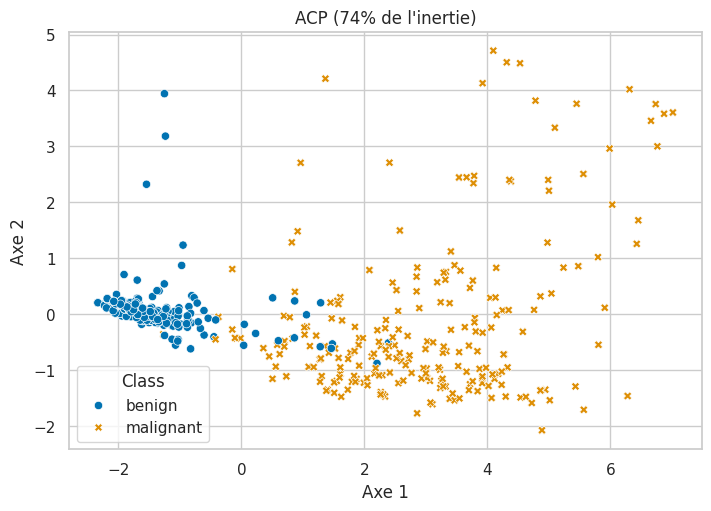

,Cl.thickness,Cell.size,Cell.shape,Marg.adhesion,Epith.c.size,Bare.nuclei,Bl.cromatin,Normal.nucleoli,Mitoses
Axe 1,0.30,0.38,0.38,0.33,0.34,0.34,0.35,0.34,0.23
Axe 2,-0.14,-0.05,-0.08,-0.05,0.16,-0.26,-0.23,0.03,0.91


In [6]:
fig, ax = plt.subplots(figsize=(7, 5), layout="constrained")
plot_map(pca_coords, tumor_class, f"ACP ({inertia['Inertie cumulée'].iloc[1]:.0%} de l'inertie)", ax,
         xlabel="Axe 1", ylabel="Axe 2")
plt.show()

loadings = pd.DataFrame(pca.components_[:2], columns=measures, index=["Axe 1", "Axe 2"])
loadings.round(2)

L'axe 1 porte à lui seul 66 % de l'inertie, et toutes les mesures y contribuent dans le même sens : c'est un axe de "gravité" de la tumeur, et les tumeurs malignes s'y séparent nettement des bénignes. L'axe 2 est presque réduit à `Mitoses`.

**3.** UMAP pour deux valeurs de `n_neighbors` :

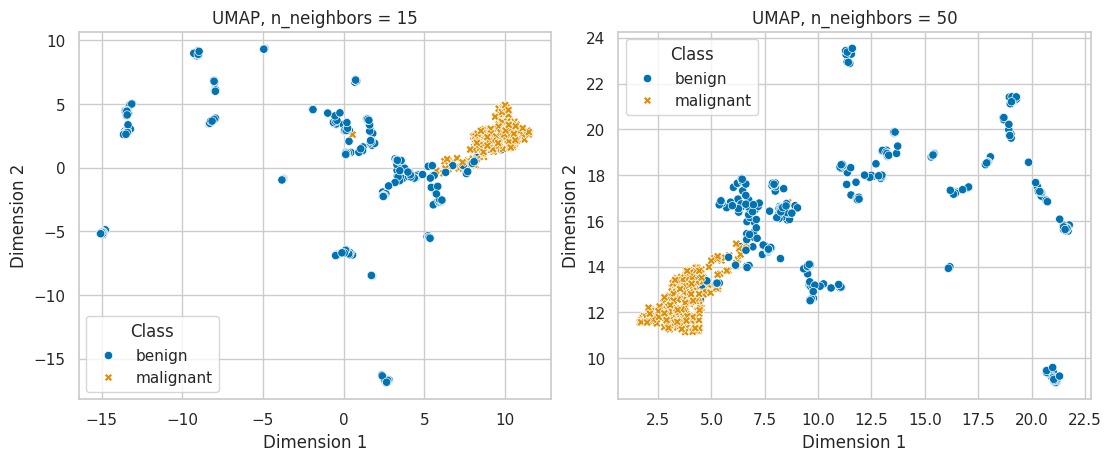

In [7]:
fig, axs = plt.subplots(1, 2, figsize=(11, 4.5), layout="constrained")
for ax, n_neighbors in zip(axs, [15, 50]):
    coords = umap.UMAP(n_neighbors=n_neighbors, min_dist=0.1, random_state=42, n_jobs=1).fit_transform(inputs_std)
    plot_map(coords, tumor_class, f"UMAP, n_neighbors = {n_neighbors}", ax)
plt.show()

Sur les deux cartes, les tumeurs malignes forment un amas compact, tandis que les tumeurs bénignes se dispersent en de nombreux petits îlots : les neuf mesures sont des notes entières de 1 à 10, et beaucoup de tumeurs bénignes ont exactement les mêmes valeurs, ce qui crée ces paquets de points superposés. La séparation bénin / malin persiste d'un réglage à l'autre, avec quelques cas mêlés ; le nombre et la position des îlots, eux, changent et ne veulent rien dire.

**4.** ACP dans une pipeline, nombre d'axes choisi par cross-validation :

In [8]:
inputs_dev, inputs_test, class_dev, class_test = \
    train_test_split(inputs, tumor_class, test_size=0.2, stratify=tumor_class, random_state=42)

pca_pipeline = make_pipeline(StandardScaler(),
                             PCA(),
                             LogisticRegression())
n_components = [1, 2, 3, 5, 9]
grid_search = GridSearchCV(pca_pipeline,
                           {"pca__n_components": n_components},
                           cv=5,
                           scoring="f1_macro")
grid_search.fit(inputs_dev, class_dev)

print(grid_search.best_params_)
print(f"F1 macro sur le test : {f1_score(class_test, grid_search.best_estimator_.predict(inputs_test), average='macro'):.2%}")
pd.DataFrame({"F1 macro de validation": grid_search.cv_results_["mean_test_score"]}, index=n_components).round(3).T

{'pca__n_components': 1}
F1 macro sur le test : 96.05%


,1,2,3,5,9
F1 macro de validation,0.97,0.97,0.97,0.968,0.968


Un seul axe suffit : il concentre l'information utile à la classification, et les axes suivants n'apportent rien. L'ACP compresse ici neuf mesures en une sans perte pour le modèle.